In [1]:
   import os
   if os.path.basename(os.getcwd()) == "notebooks":
       os.chdir("..")

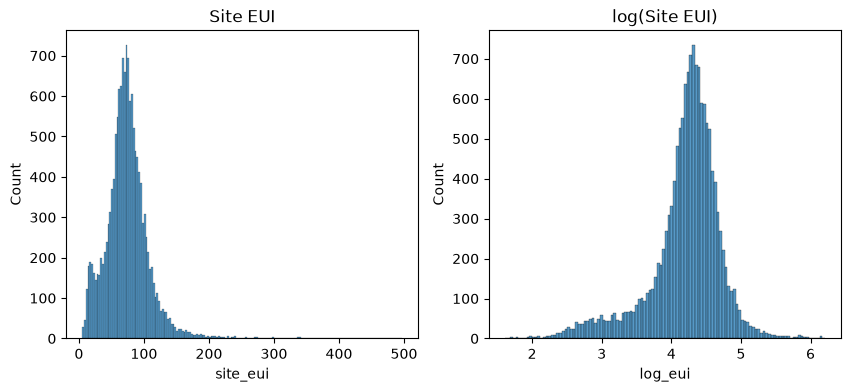

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_parquet("data/clean/ll84_clean.parquet")
df["log_eui"] = np.log(df["site_eui"])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df["site_eui"], ax=ax[0]).set_title("Site EUI")
sns.histplot(df["log_eui"], ax=ax[1]).set_title("log(Site EUI)")
plt.show()

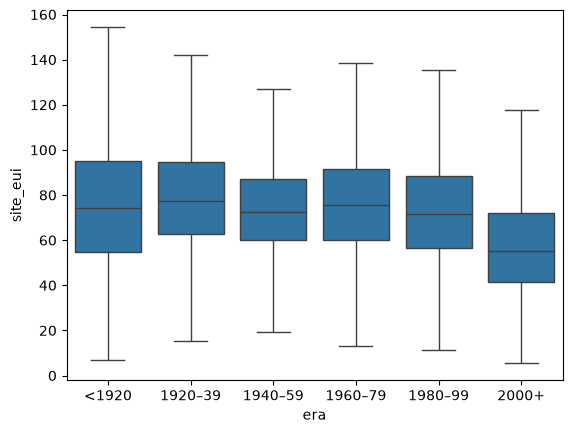

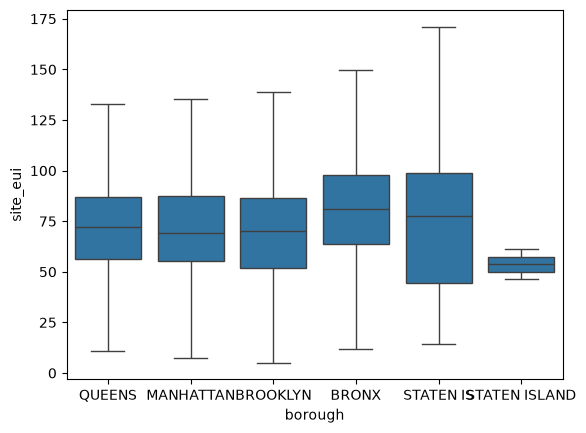

             site_eui  year_built       gfa  energy_star
site_eui     1.000000   -0.202393 -0.167159    -0.802153
year_built  -0.202393    1.000000  0.290890     0.053115
gfa         -0.167159    0.290890  1.000000     0.077589
energy_star -0.802153    0.053115  0.077589     1.000000


In [3]:
df["era"] = pd.cut(df["year_built"],
                   [1800, 1920, 1940, 1960, 1980, 2000, 2025],
                   labels=["<1920", "1920–39", "1940–59", "1960–79", "1980–99", "2000+"])
sns.boxplot(data=df, x="era", y="site_eui", showfliers=False)
plt.show()
sns.boxplot(data=df, x="borough", y="site_eui", showfliers=False)
plt.show()
print(df[["site_eui", "year_built", "gfa", "energy_star"]].corr(method="spearman"))

In [4]:
from scipy import stats

old = df.loc[df["year_built"] < 1940, "log_eui"]
new = df.loc[df["year_built"] > 1980, "log_eui"]
t, p = stats.ttest_ind(old, new, equal_var=False)
ratio = np.exp(old.mean() - new.mean())
print(f"t = {t:.2f}, p = {p:.2g}")
print(f"Older buildings use {100*(ratio-1):.0f}% more energy per ft² (geometric mean)")

t = 21.18, p = 1.6e-96
Older buildings use 24% more energy per ft² (geometric mean)


Seems reasonable, have only done a handful pre 1940's so don't have much anecdotal experience. All of them had very very high ACH, one was 20+ iirc, and most had older non-electric heating systems or just baseboards. Also energy use seems to drop off heavily post 2000's


In [5]:
import statsmodels.formula.api as smf

df["log_gfa"] = np.log(df["gfa"])
model = smf.ols('log_eui ~ C(era, Treatment(reference="2000+")) + log_gfa + C(borough)',
                data=df).fit()
print(f"R² = {model.rsquared:.3f}")

pct = (np.exp(model.params.filter(like="era")) - 1) * 100
print(pct.round(1))

R² = 0.049
C(era, Treatment(reference="2000+"))[T.<1920]      23.0
C(era, Treatment(reference="2000+"))[T.1920–39]    30.9
C(era, Treatment(reference="2000+"))[T.1940–59]    28.1
C(era, Treatment(reference="2000+"))[T.1960–79]    34.8
C(era, Treatment(reference="2000+"))[T.1980–99]    26.0
dtype: float64


age/size/borough explain less than 6% of the variation of energy use


In [6]:
ci = (np.exp(model.conf_int().filter(like="era", axis=0)) - 1) * 100
print(ci.round(1))

                                                    0     1
C(era, Treatment(reference="2000+"))[T.<1920]    19.3  26.9
C(era, Treatment(reference="2000+"))[T.1920–39]  27.7  34.1
C(era, Treatment(reference="2000+"))[T.1940–59]  24.1  32.2
C(era, Treatment(reference="2000+"))[T.1960–79]  30.4  39.4
C(era, Treatment(reference="2000+"))[T.1980–99]  21.2  31.1


given so much overlap, can't conclude much about pre-2000's, but there is a stark difference past 2000, maybe the building codes/standards changed over there

In [7]:
   recent = df[df["year_built"] >= 1980].copy()
   recent["bin5"] = (recent["year_built"] // 5) * 5
   print(recent.groupby("bin5")["site_eui"].agg(["median", "count"]))

      median  count
bin5               
1980   75.40    194
1985   68.95    346
1990   75.70    173
1995   69.80    149
2000   70.20    355
2005   62.95    726
2010   57.60    409
2015   49.80    771
2020   39.80    344


The 2010 building code change in NY didnt start the decline, so it isn't just that

In [8]:
new = df[df["year_built"] >= 2020]
print(new.groupby(new["year_built"])["site_eui"].agg(["median", "count"]))

            median  count
year_built               
2020          48.3    103
2021          39.5    106
2022          35.8    135


Went back to remove the newest buildings (2023+) since the numbers could have been affected by occupancy rates, numbers kind of seemed like outliers?